In [41]:
import pandas as pd
import numpy as np

In [42]:
data=pd.read_csv("online_retail_II.csv")

In [43]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       --------------    -----  
 0   Invoice      1067371 non-null  object 
 1   StockCode    1067371 non-null  object 
 2   Description  1062989 non-null  object 
 3   Quantity     1067371 non-null  int64  
 4   InvoiceDate  1067371 non-null  object 
 5   Price        1067371 non-null  float64
 6   Customer ID  824364 non-null   float64
 7   Country      1067371 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 65.1+ MB


In [44]:
data.shape

(1067371, 8)

In [45]:
data.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [46]:
data.isna().sum()

Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64

In [47]:
data.duplicated().sum()

34335

In [48]:
data.describe(include="all")

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
count,1067371,1067371,1062989,1.067371e+06,1067371,1.067371e+06,824364.000000,1067371
unique,53628,5305,5698,NaN,47635,NaN,NaN,43
top,537434,85123A,WHITE HANGING HEART T-LIGHT HOLDER,NaN,2010-12-06 16:57:00,NaN,NaN,United Kingdom
freq,1350,5829,5918,NaN,1350,NaN,NaN,981330
mean,NaN,NaN,NaN,9.938898e+00,NaN,4.649388e+00,15324.638504,NaN
std,NaN,NaN,NaN,1.727058e+02,NaN,1.235531e+02,1697.464450,NaN
min,NaN,NaN,NaN,-8.099500e+04,NaN,-5.359436e+04,12346.000000,NaN
25%,NaN,NaN,NaN,1.000000e+00,NaN,1.250000e+00,13975.000000,NaN
50%,NaN,NaN,NaN,3.000000e+00,NaN,2.100000e+00,15255.000000,NaN
75%,NaN,NaN,NaN,1.000000e+01,NaN,4.150000e+00,16797.000000,NaN


In [49]:
missing_count=data.isnull().sum()
missing_count

Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64

In [50]:
# find the most common description for each StockCode
description_map = (data.dropna(subset=["Description"]).groupby("StockCode")["Description"].agg(lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan))

# fill missing descriptions
data["Description"] = data["Description"].fillna(data["StockCode"].map(description_map))

In [51]:
# Retain missing Customer IDs
# Convert to nullable integer

data["Customer ID"] = data["Customer ID"].astype("Int64")

In [52]:
missing_count=data.isnull().sum()
missing_count

Invoice             0
StockCode           0
Description       363
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64

In [53]:
data.duplicated().sum()

34335

In [54]:
data=data.drop_duplicates()

In [56]:
data.shape

(1033036, 8)

In [57]:
data.duplicated().sum()

0

In [58]:
data.dtypes

Invoice         object
StockCode       object
Description     object
Quantity         int64
InvoiceDate     object
Price          float64
Customer ID      Int64
Country         object
dtype: object

In [59]:
data["InvoiceDate"] = pd.to_datetime(data["InvoiceDate"])
data["Country"] = data["Country"].astype("category")

In [60]:
data.dtypes

Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
Price                 float64
Customer ID             Int64
Country              category
dtype: object

In [62]:
print("Negative quantities:",
      (data["Quantity"] < 0).sum())

print("Zero quantities:",
      (data["Quantity"] == 0).sum())

print("Positive quantities:",
      (data["Quantity"] > 0).sum())

print("\nQuantity summary:")
print(data["Quantity"].describe())

Negative quantities: 22496
Zero quantities: 0
Positive quantities: 1010540

Quantity summary:
count    1.033036e+06
mean     1.007688e+01
std      1.751976e+02
min     -8.099500e+04
25%      1.000000e+00
50%      3.000000e+00
75%      1.000000e+01
max      8.099500e+04
Name: Quantity, dtype: float64


In [65]:
# Display sample negative quantity transactions

negative_qty = data[data["Quantity"] < 0]

print(
    negative_qty[
        ["Invoice", "StockCode", "Description",
         "Quantity", "InvoiceDate", "Price"]
    ].head(10)
)

     Invoice StockCode                        Description  Quantity  \
178  C489449     22087           PAPER BUNTING WHITE LACE       -12   
179  C489449    85206A       CREAM FELT EASTER EGG BASKET        -6   
180  C489449     21895      POTTING SHED SOW 'N' GROW SET        -4   
181  C489449     21896                 POTTING SHED TWINE        -6   
182  C489449     22083         PAPER CHAIN KIT RETRO SPOT       -12   
183  C489449     21871                SAVE THE PLANET MUG       -12   
184  C489449     84946    ANTIQUE SILVER TEA GLASS ETCHED       -12   
185  C489449    84970S  HANGING HEART ZINC T-LIGHT HOLDER       -24   
186  C489449     22090          PAPER BUNTING RETRO SPOTS       -12   
196  C489459    90200A         PURPLE SWEETHEART BRACELET        -3   

            InvoiceDate  Price  
178 2009-12-01 10:33:00   2.95  
179 2009-12-01 10:33:00   1.65  
180 2009-12-01 10:33:00   4.25  
181 2009-12-01 10:33:00   2.10  
182 2009-12-01 10:33:00   2.95  
183 2009-12-01 10:33

In [66]:
# Display sample negative quantity transactions

negative_qty = data[data["Quantity"] < 0]

print(
    negative_qty[
        ["Invoice", "StockCode", "Description",
         "Quantity", "InvoiceDate", "Price"]
    ].head(10)
)

     Invoice StockCode                        Description  Quantity  \
178  C489449     22087           PAPER BUNTING WHITE LACE       -12   
179  C489449    85206A       CREAM FELT EASTER EGG BASKET        -6   
180  C489449     21895      POTTING SHED SOW 'N' GROW SET        -4   
181  C489449     21896                 POTTING SHED TWINE        -6   
182  C489449     22083         PAPER CHAIN KIT RETRO SPOT       -12   
183  C489449     21871                SAVE THE PLANET MUG       -12   
184  C489449     84946    ANTIQUE SILVER TEA GLASS ETCHED       -12   
185  C489449    84970S  HANGING HEART ZINC T-LIGHT HOLDER       -24   
186  C489449     22090          PAPER BUNTING RETRO SPOTS       -12   
196  C489459    90200A         PURPLE SWEETHEART BRACELET        -3   

            InvoiceDate  Price  
178 2009-12-01 10:33:00   2.95  
179 2009-12-01 10:33:00   1.65  
180 2009-12-01 10:33:00   4.25  
181 2009-12-01 10:33:00   2.10  
182 2009-12-01 10:33:00   2.95  
183 2009-12-01 10:33

In [67]:
print(
    "Negative quantities with C invoices:",
    negative_qty["Invoice"].str.startswith("C").sum()
)

print(
    "Total negative quantities:",
    len(negative_qty)
)

Negative quantities with C invoices: 19103
Total negative quantities: 22496


In [69]:
print(
    "Fractional quantities:",
    (data["Quantity"] % 1 != 0).sum()
)

Fractional quantities: 0


In [70]:
data["Quantity"] = data["Quantity"].astype("int64")

In [71]:
# Check negative, zero and positive prices

print("Negative prices:",
      (data["Price"] < 0).sum())

print("Zero prices:",
      (data["Price"] == 0).sum())

print("Positive prices:",
      (data["Price"] > 0).sum())

print("\nPrice summary:")
print(data["Price"].describe())

Negative prices: 5
Zero prices: 6014
Positive prices: 1027017

Price summary:
count    1.033036e+06
mean     4.613980e+00
std      1.223975e+02
min     -5.359436e+04
25%      1.250000e+00
50%      2.100000e+00
75%      4.150000e+00
max      3.897000e+04
Name: Price, dtype: float64


In [72]:
negative_price = data[data["Price"] < 0]

print(
    negative_price[
        ["Invoice", "StockCode", "Description",
         "Quantity", "Price"]
    ]
)

        Invoice StockCode      Description  Quantity     Price
179403  A506401         B  Adjust bad debt         1 -53594.36
276274  A516228         B  Adjust bad debt         1 -44031.79
403472  A528059         B  Adjust bad debt         1 -38925.87
825444  A563186         B  Adjust bad debt         1 -11062.06
825445  A563187         B  Adjust bad debt         1 -11062.06


In [73]:
zero_price = data[data["Price"] == 0]

print(
    zero_price[
        ["Invoice", "StockCode", "Description",
         "Quantity", "Price"]
    ].head(15)
)

     Invoice StockCode                       Description  Quantity  Price
263   489464     21733                      85123a mixed       -96    0.0
283   489463     71477                             short      -240    0.0
284   489467    85123A                       21733 mixed      -192    0.0
470   489521     21646                               NaN       -50    0.0
3114  489655     20683         RAIN GIRL CHILDS UMBRELLA       -44    0.0
3161  489659     21350              GINGHAM HEART WREATH       230    0.0
3162  489660     35956                              lost     -1043    0.0
3168  489663    35605A                           damages      -117    0.0
3731  489781     84292     ROSE PINK METAL FOLDING CHAIR        17    0.0
4296  489806     18010  ASSORTED FRAGRANCE BATH CONFETTI      -770    0.0
4538  489820     21133                   invcd as 84879?      -720    0.0
4566  489821    85049G            CHOCOLATE BOX RIBBONS       -240    0.0
4674  489825     22076                

In [74]:
# Identify cancellation invoices

cancelled = data[
    data["Invoice"].astype(str).str.startswith("C")
]

print("Total cancellation records:", len(cancelled))

print("Unique cancellation invoices:",
      cancelled["Invoice"].nunique())

print("Total records in dataset:", len(data))

Total cancellation records: 19104
Unique cancellation invoices: 8292
Total records in dataset: 1033036


In [75]:
print("Positive quantities in cancellations:",
      (cancelled["Quantity"] > 0).sum())

print("Negative quantities in cancellations:",
      (cancelled["Quantity"] < 0).sum())

print("Zero quantities in cancellations:",
      (cancelled["Quantity"] == 0).sum())

Positive quantities in cancellations: 1
Negative quantities in cancellations: 19103
Zero quantities in cancellations: 0


In [76]:
Q1 = data["Quantity"].quantile(0.25)
Q3 = data["Quantity"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

quantity_outliers = data[
    (data["Quantity"] < lower) |
    (data["Quantity"] > upper)
]

print("Quantity lower limit:", lower)
print("Quantity upper limit:", upper)

print("Quantity outliers:", len(quantity_outliers))

Quantity lower limit: -12.5
Quantity upper limit: 23.5
Quantity outliers: 114434


In [77]:
Q1 = data["Price"].quantile(0.25)
Q3 = data["Price"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

price_outliers = data[
    (data["Price"] < lower) |
    (data["Price"] > upper)
]

print("Price lower limit:", lower)
print("Price upper limit:", upper)

print("Price outliers:", len(price_outliers))

Price lower limit: -3.1000000000000005
Price upper limit: 8.5
Price outliers: 66196


In [78]:

# ==========================================
# FINAL DATA QUALITY VALIDATION
# ==========================================

print("DATASET SHAPE:", data.shape)

# 1. Check missing values
print("\nMissing Values:")
print(data.isnull().sum())

# 2. Check duplicate records
print("\nDuplicate Records:")
print(data.duplicated().sum())

# 3. Check data types
print("\nData Types:")
print(data.dtypes)

# 4. Check Quantity
print("\nQuantity Validation:")
print("Negative:", (data["Quantity"] < 0).sum())
print("Zero:", (data["Quantity"] == 0).sum())
print("Positive:", (data["Quantity"] > 0).sum())

# 5. Check Price
print("\nPrice Validation:")
print("Negative:", (data["Price"] < 0).sum())
print("Zero:", (data["Price"] == 0).sum())
print("Positive:", (data["Price"] > 0).sum())

# 6. Check InvoiceDate
print("\nInvoice Date Range:")
print(data["InvoiceDate"].min())
print(data["InvoiceDate"].max())


DATASET SHAPE: (1033036, 8)

Missing Values:
Invoice             0
StockCode           0
Description       363
Quantity            0
InvoiceDate         0
Price               0
Customer ID    235151
Country             0
dtype: int64

Duplicate Records:
0

Data Types:
Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
Price                 float64
Customer ID             Int64
Country              category
dtype: object

Quantity Validation:
Negative: 22496
Zero: 0
Positive: 1010540

Price Validation:
Negative: 5
Zero: 6014
Positive: 1027017

Invoice Date Range:
2009-12-01 07:45:00
2011-12-09 12:50:00


In [79]:
data.to_csv("online_retail_II_cleaned.csv", index=False)

In [80]:
numerical_columns = ["Quantity", "Price"]

for col in numerical_columns:

    print("\n", "=" * 40)
    print("STATISTICAL ANALYSIS:", col)
    print("=" * 40)

    print("Count:", data[col].count())
    print("Mean:", data[col].mean())
    print("Median:", data[col].median())
    print("Mode:", data[col].mode().iloc[0])
    print("Standard Deviation:", data[col].std())
    print("Minimum:", data[col].min())
    print("Maximum:", data[col].max())
    print("Range:", data[col].max() - data[col].min())

    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)

    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", Q3 - Q1)

    print("Skewness:", data[col].skew())



STATISTICAL ANALYSIS: Quantity
Count: 1033036
Mean: 10.076879218149223
Median: 3.0
Mode: 1
Standard Deviation: 175.19762799665853
Minimum: -80995
Maximum: 80995
Range: 161990
Q1: 1.0
Q3: 10.0
IQR: 9.0
Skewness: 4.0921951415729785

STATISTICAL ANALYSIS: Price
Count: 1033036
Mean: 4.613979656081683
Median: 2.1
Mode: 1.25
Standard Deviation: 122.39752328600267
Minimum: -53594.36
Maximum: 38970.0
Range: 92564.36
Q1: 1.25
Q3: 4.15
IQR: 2.9000000000000004
Skewness: -78.97640639334982


In [81]:
# relations


# ==========================================
# QUANTITY VS PRICE CORRELATION
# ==========================================

# 1. Pearson correlation (all records)

pearson_all = data["Quantity"].corr(
    data["Price"],
    method="pearson"
)

# 2. Spearman correlation (all records)

spearman_all = data["Quantity"].corr(
    data["Price"],
    method="spearman"
)

print("ALL RECORDS")
print("Pearson correlation:", pearson_all)
print("Spearman correlation:", spearman_all)


# ==========================================
# ANALYSE ORDINARY POSITIVE SALES
# ==========================================

# Exclude returns, zero-price records,
# negative-price adjustments and cancellation invoices.

sales_data = data[
    (data["Quantity"] > 0) &
    (data["Price"] > 0) &
    (~data["Invoice"].astype(str).str.startswith("C"))
]

# Pearson correlation

pearson_sales = sales_data["Quantity"].corr(
    sales_data["Price"],
    method="pearson"
)

# Spearman correlation

spearman_sales = sales_data["Quantity"].corr(
    sales_data["Price"],
    method="spearman"
)

print("\nORDINARY POSITIVE SALES")
print("Records:", len(sales_data))
print("Pearson correlation:", pearson_sales)
print("Spearman correlation:", spearman_sales)


ALL RECORDS
Pearson correlation: -0.0013170267688523564
Spearman correlation: -0.40580999363975023

ORDINARY POSITIVE SALES
Records: 1007913
Pearson correlation: -0.003855451076565449
Spearman correlation: -0.427946586388068


In [82]:
# Calculate transaction-level revenue

sales_data = sales_data.copy()

sales_data["Revenue"] = (
    sales_data["Quantity"] * sales_data["Price"]
)

print(sales_data[
    ["StockCode", "Description",
     "Quantity", "Price", "Revenue"]
].head())

  StockCode                          Description  Quantity  Price  Revenue
0     85048  15CM CHRISTMAS GLASS BALL 20 LIGHTS        12   6.95     83.4
1    79323P                   PINK CHERRY LIGHTS        12   6.75     81.0
2    79323W                  WHITE CHERRY LIGHTS        12   6.75     81.0
3     22041         RECORD FRAME 7" SINGLE SIZE         48   2.10    100.8
4     21232       STRAWBERRY CERAMIC TRINKET BOX        24   1.25     30.0


In [83]:
top_quantity = (
    sales_data.groupby(
        ["StockCode", "Description"]
    )["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 Products by Quantity:")
print(top_quantity)

Top 10 Products by Quantity:
StockCode  Description                       
84077      WORLD WAR 2 GLIDERS ASSTD DESIGNS     106139
85123A     WHITE HANGING HEART T-LIGHT HOLDER     94142
23843      PAPER CRAFT , LITTLE BIRDIE            80995
84879      ASSORTED COLOUR BIRD ORNAMENT          80082
23166      MEDIUM CERAMIC TOP STORAGE JAR         78033
85099B     JUMBO BAG RED RETROSPOT                77280
17003      BROCADE RING PURSE                     70369
21977      PACK OF 60 PINK PAISLEY CAKE CASES     56061
84991      60 TEATIME FAIRY CAKE CASES            54028
22197      SMALL POPCORN HOLDER                   48561
Name: Quantity, dtype: int64


In [84]:
top_price = (
    sales_data.groupby(
        ["StockCode", "Description"]
    )["Price"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 Products by Average Price:")
print(top_price)

Top 10 Products by Average Price:
StockCode  Description                        
B          Adjust bad debt                        11062.060000
AMAZONFEE  AMAZON FEE                              6822.600000
22502      PICNIC BASKET WICKER 60 PIECES           649.500000
ADJUST     Adjustment by john on 26/01/2010 17      410.218750
M          Manual                                   394.318014
ADJUST2    Adjustment by Peter on Jun 25 2010       243.683333
DOT        DOTCOM POSTAGE                           218.978170
22656      VINTAGE BLUE KITCHEN CABINET             214.864865
22655      VINTAGE RED KITCHEN CABINET              186.320755
22827      RUSTIC  SEVENTEEN DRAWER SIDEBOARD       158.793103
Name: Price, dtype: float64


In [85]:
top_revenue = (
    sales_data.groupby(
        ["StockCode", "Description"]
    )["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 Products by Revenue:")
print(top_revenue)

Top 10 Products by Revenue:
StockCode  Description                       
M          Manual                                339226.24
22423      REGENCY CAKESTAND 3 TIER              330590.32
DOT        DOTCOM POSTAGE                        309854.11
85123A     WHITE HANGING HEART T-LIGHT HOLDER    257546.20
23843      PAPER CRAFT , LITTLE BIRDIE           168469.60
47566      PARTY BUNTING                         148318.28
85099B     JUMBO BAG RED RETROSPOT               145961.83
84879      ASSORTED COLOUR BIRD ORNAMENT         129324.49
POST       POSTAGE                               125682.42
22086      PAPER CHAIN KIT 50'S CHRISTMAS        117760.29
Name: Revenue, dtype: float64


In [86]:
# Top 10 products by total quantity sold

top_products = (
    sales_data.groupby(
        ["StockCode", "Description"]
    )["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_products)

StockCode  Description                       
84077      WORLD WAR 2 GLIDERS ASSTD DESIGNS     106139
85123A     WHITE HANGING HEART T-LIGHT HOLDER     94142
23843      PAPER CRAFT , LITTLE BIRDIE            80995
84879      ASSORTED COLOUR BIRD ORNAMENT          80082
23166      MEDIUM CERAMIC TOP STORAGE JAR         78033
85099B     JUMBO BAG RED RETROSPOT                77280
17003      BROCADE RING PURSE                     70369
21977      PACK OF 60 PINK PAISLEY CAKE CASES     56061
84991      60 TEATIME FAIRY CAKE CASES            54028
22197      SMALL POPCORN HOLDER                   48561
Name: Quantity, dtype: int64


In [87]:
# Calculate revenue
sales_data["Revenue"] = (
    sales_data["Quantity"] * sales_data["Price"]
)

# Country-wise revenue
country_revenue = (
    sales_data.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

# Display top 10 countries
print(country_revenue.head(10))

Country
United Kingdom    1.741020e+07
EIRE              6.587673e+05
Netherlands       5.540381e+05
Germany           4.250197e+05
France            3.504561e+05
Australia         1.692835e+05
Spain             1.083325e+05
Switzerland       1.006856e+05
Sweden            9.186982e+04
Denmark           6.858069e+04
Name: Revenue, dtype: float64


C:\Users\Manoj\AppData\Local\Temp\ipykernel_9276\266399898.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  sales_data.groupby("Country")["Revenue"]


In [88]:
# Extract year and month

sales_data["YearMonth"] = (
    sales_data["InvoiceDate"].dt.to_period("M")
)

# Calculate monthly revenue

monthly_revenue = (
    sales_data.groupby("YearMonth")["Revenue"]
    .sum()
    .sort_index()
)

print("Monthly Revenue:")
print(monthly_revenue)

Monthly Revenue:
YearMonth
2009-12     822483.950
2010-01     651155.112
2010-02     551504.726
2010-03     830915.261
2010-04     678875.252
2010-05     657705.500
2010-06     749537.310
2010-07     648810.270
2010-08     695251.910
2010-09     921696.991
2010-10    1161902.220
2010-11    1464293.142
2010-12     821452.730
2011-01     689811.610
2011-02     522545.560
2011-03     716215.260
2011-04     536968.491
2011-05     769296.610
2011-06     760547.010
2011-07     718076.121
2011-08     757841.380
2011-09    1056435.192
2011-10    1151263.730
2011-11    1503866.780
2011-12     637808.330
Freq: M, Name: Revenue, dtype: float64


In [89]:
# Customer purchase frequency

customer_frequency = (
    sales_data.groupby("Customer ID")["Invoice"]
    .nunique()
    .sort_values(ascending=False)
)

print("Top 10 Customers by Purchase Frequency:")
print(customer_frequency.head(10))

Top 10 Customers by Purchase Frequency:
Customer ID
14911    398
12748    336
17841    211
15311    208
13089    203
14606    192
14156    156
17850    155
14646    151
18102    145
Name: Invoice, dtype: int64


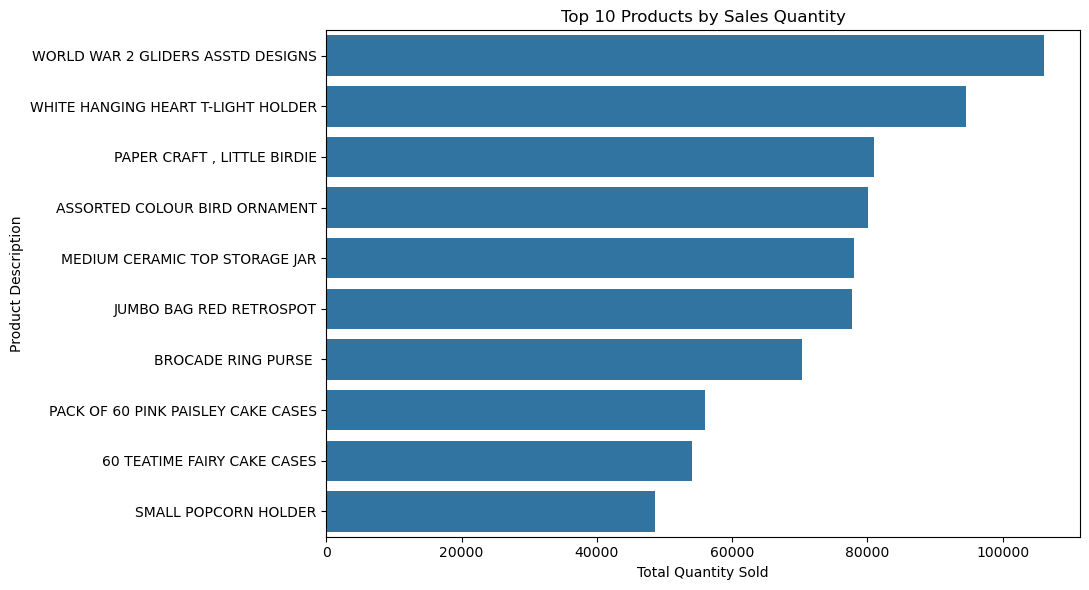

In [92]:

import matplotlib.pyplot as plt
import seaborn as sns

# Calculate top 10 products by quantity

top_products = (
    sales_data.groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

# Create horizontal bar chart

plt.figure(figsize=(11, 6))

sns.barplot(
    data=top_products,
    x="Quantity",
    y="Description"
)

plt.title("Top 10 Products by Sales Quantity")
plt.xlabel("Total Quantity Sold")
plt.ylabel("Product Description")

plt.tight_layout()
plt.show()


          Country       Revenue
0  United Kingdom  1.741020e+07
1            EIRE  6.587673e+05
2     Netherlands  5.540381e+05
3         Germany  4.250197e+05
4          France  3.504561e+05
5       Australia  1.692835e+05
6           Spain  1.083325e+05
7     Switzerland  1.006856e+05
8          Sweden  9.186982e+04
9         Denmark  6.858069e+04


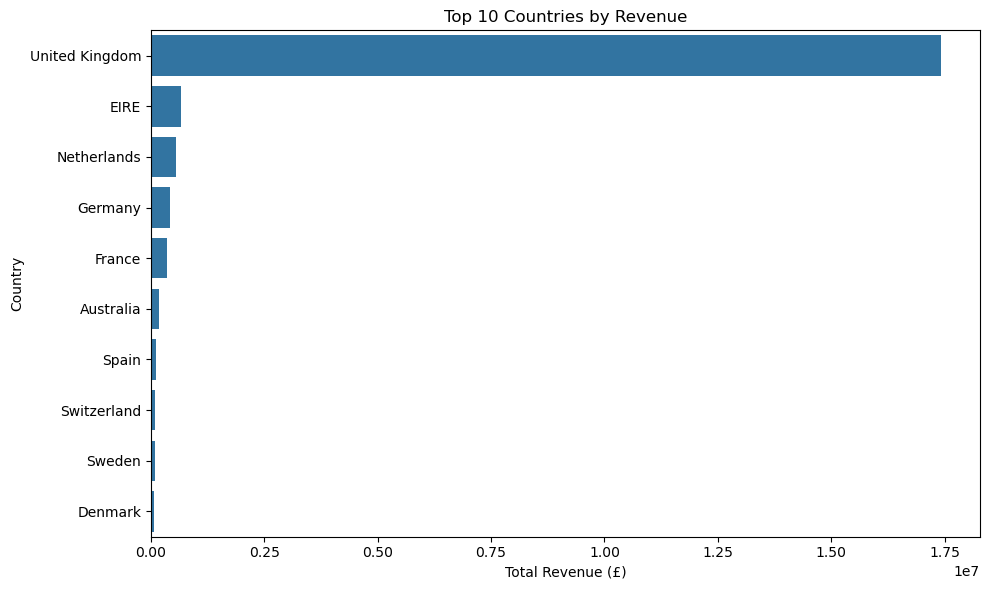

In [94]:
# Calculate top 10 countries by revenue

top_countries = (
    sales_data.groupby("Country", observed=True)["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

# Convert Country to string for plotting
top_countries["Country"] = top_countries["Country"].astype(str)

# Display top 10 countries
print(top_countries)

# Create horizontal bar chart

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_countries,
    x="Revenue",
    y="Country"
)

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Total Revenue (£)")
plt.ylabel("Country")

plt.tight_layout()
plt.show()

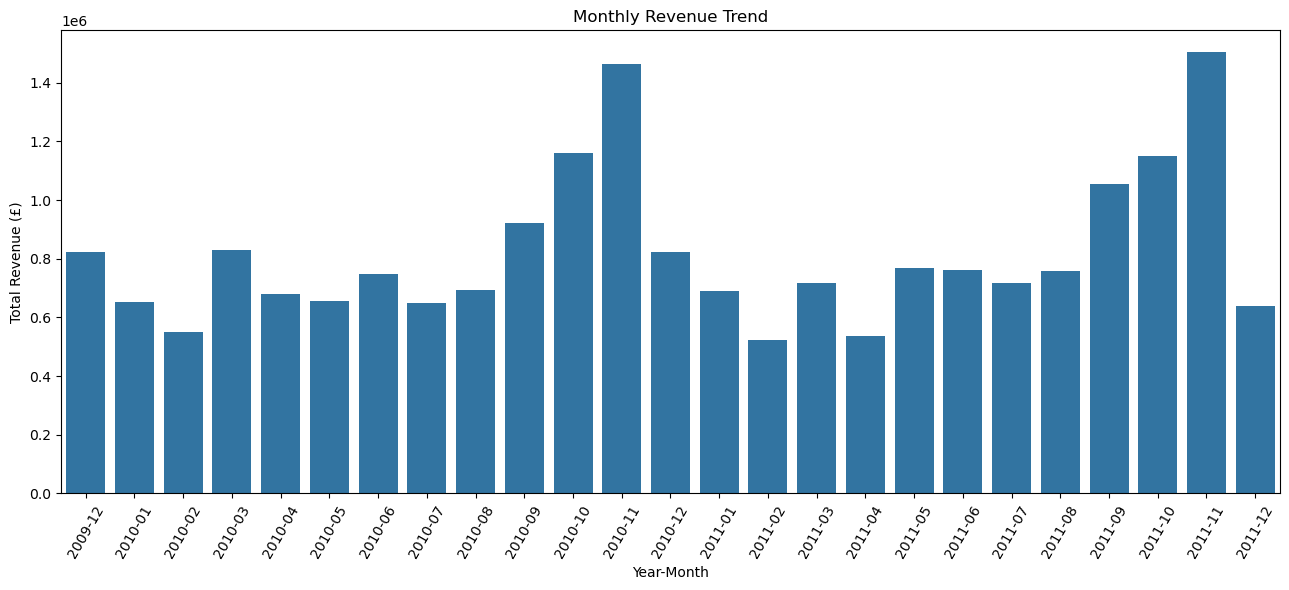

In [95]:
# Convert monthly revenue into a DataFrame

monthly_data = monthly_revenue.reset_index()

monthly_data["YearMonth"] = (
    monthly_data["YearMonth"].astype(str)
)

# Create bar chart

plt.figure(figsize=(13, 6))

sns.barplot(
    data=monthly_data,
    x="YearMonth",
    y="Revenue"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Year-Month")
plt.ylabel("Total Revenue (£)")

plt.xticks(rotation=60)

plt.tight_layout()
plt.show()

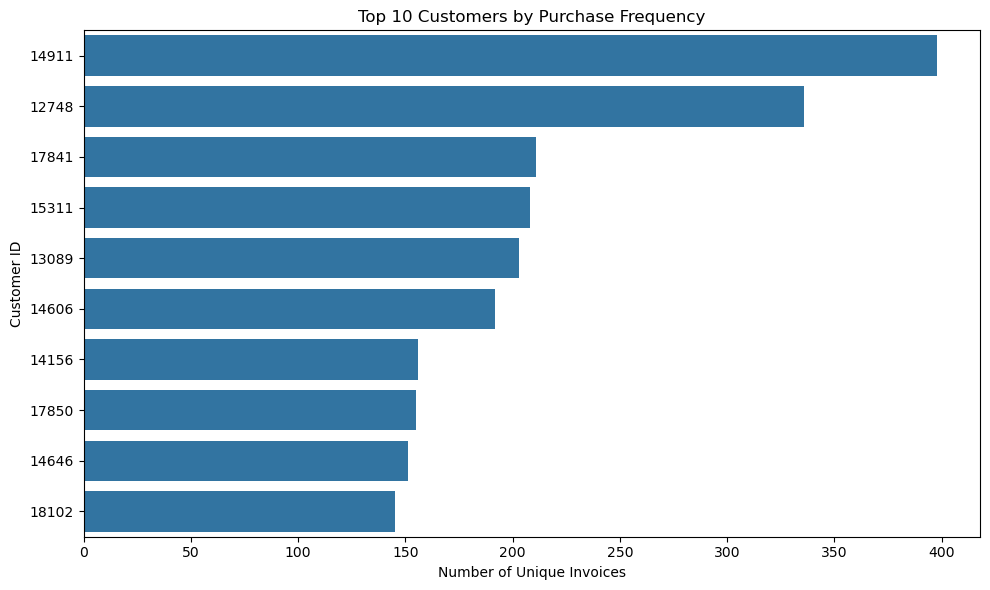

In [96]:
# Top 10 customers by purchase frequency

top_customers = (
    customer_frequency
    .head(10)
    .reset_index()
)

top_customers["Customer ID"] = (
    top_customers["Customer ID"].astype(str)
)

# Create horizontal bar chart

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_customers,
    x="Invoice",
    y="Customer ID"
)

plt.title("Top 10 Customers by Purchase Frequency")
plt.xlabel("Number of Unique Invoices")
plt.ylabel("Customer ID")

plt.tight_layout()
plt.show()